In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [37]:
# Load the dataset
df = pd.read_csv("../data/raw/ecommerce_sales_data.csv")

# Display first 5 rows
df.head()

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
0,2024-12-31,Printer,Office,North,4,3640,348.93
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73
3,2024-03-16,Mouse,Accessories,South,2,786,202.87
4,2022-09-10,Mouse,Accessories,West,1,509,103.28


In [3]:
# Convert Order Date into datetime format

df['Order Date'] = pd.to_datetime(df['Order Date'])

# Verify data type

print(df['Order Date'].dtype)

datetime64[ns]


In [5]:
df.dtypes

Order Date      datetime64[ns]
Product Name            object
Category                object
Region                  object
Quantity                 int64
Sales                    int64
Profit                 float64
dtype: object

### Create Date Features

In [6]:
# Extract date-related information

df['Year'] = df['Order Date'].dt.year

df['Month'] = df['Order Date'].dt.month

df['Month_Name'] = df['Order Date'].dt.month_name()

df['Quarter'] = df['Order Date'].dt.quarter

df['Year_Month'] = df['Order Date'].dt.to_period('M')

# Display updated dataset

df.head()

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
0,2024-12-31,Printer,Office,North,4,3640,348.93,2024,12,December,4,2024-12
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53,2022,11,November,4,2022-11
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73,2022,5,May,2,2022-05
3,2024-03-16,Mouse,Accessories,South,2,786,202.87,2024,3,March,1,2024-03
4,2022-09-10,Mouse,Accessories,West,1,509,103.28,2022,9,September,3,2022-09


In [36]:
# Save the updated dataset for further analysis
df.to_csv("../data/processed/ecommerce_processed_dataset.csv", index=False)

print("EDA dataset saved successfully!")

EDA dataset saved successfully!


### Univariate Analysis

In [7]:
# Numerical Summary
df[['Quantity', 'Sales', 'Profit']].describe()

,Quantity,Sales,Profit
count,3500.000000,3500.000000,3500.000000
mean,4.931714,3047.966000,527.047203
std,2.575895,2440.213237,504.139732
min,1.000000,51.000000,6.970000
25%,3.000000,1049.500000,158.695000
50%,5.000000,2350.500000,361.070000
75%,7.000000,4537.000000,729.125000
max,9.000000,10782.000000,2946.930000


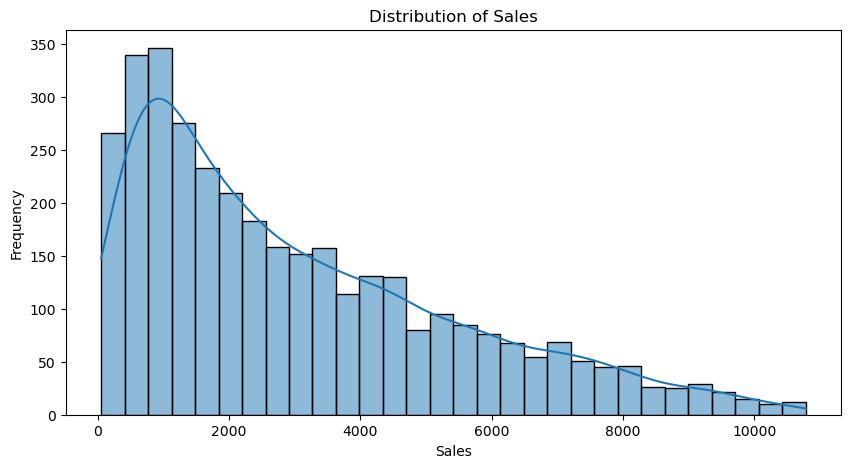

In [8]:
# Distribution of Sales
plt.figure(figsize=(10,5))
sns.histplot(df['Sales'], bins=30, kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()


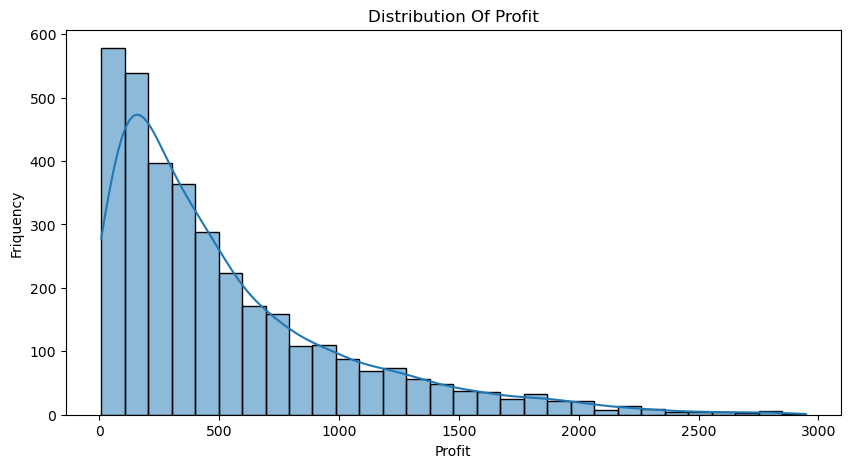

In [9]:
# Distribution of Profit
plt.figure(figsize=(10,5))

sns.histplot(df['Profit'], bins=30, kde=True)

plt.title("Distribution Of Profit")
plt.xlabel("Profit")
plt.ylabel("Friquency")

plt.show()

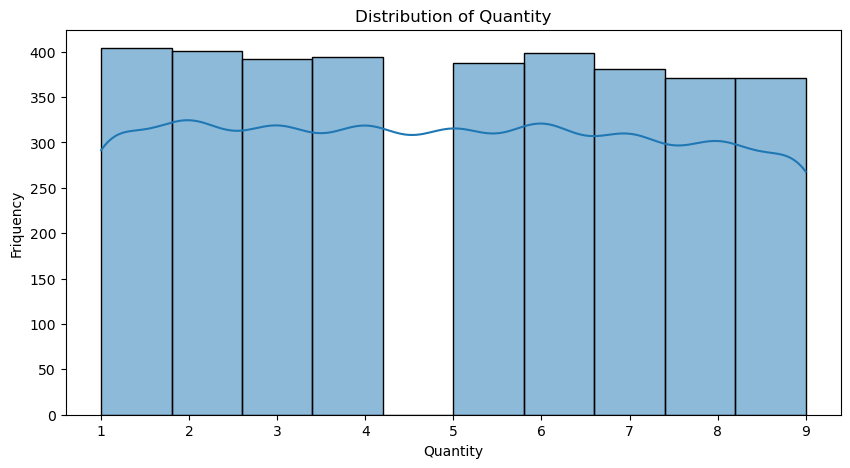

In [12]:
# Distribution of Quantity
plt.figure(figsize=(10,5))

sns.histplot(df['Quantity'], bins=10, kde=True)

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Friquency")

plt.show()

### Outlier Investigation

In [ ]:
# Identify Sales Outliers
Q1 = df['Sales'].quantile(0.25)

Q3 = df['Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

sales_outliers = df[
    (df['Sales'] < lower_limit) |
    (df['Sales'] > upper_limit)
]

print("Sales Outliers:", len(sales_outliers))

sales_outliers.head()

Sales Outliers: 35


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
32,2023-04-09,Laptop,Electronics,North,9,10773,1907.36,2023,4,April,2,2023-04
147,2022-10-23,Keyboard,Accessories,West,9,10035,1486.30,2022,10,October,4,2022-10
153,2024-08-08,Monitor,Accessories,North,9,10530,2387.63,2024,8,August,3,2024-08
267,2024-01-25,Tablet,Electronics,East,9,10188,2165.78,2024,1,January,1,2024-01
293,2023-08-08,Monitor,Accessories,North,9,10458,2799.48,2023,8,August,3,2023-08


In [14]:
df['Quantity'].value_counts()

Quantity
1    404
2    401
6    399
4    394
3    392
5    387
7    381
9    371
8    371
Name: count, dtype: int64

In [ ]:
# Identify Profit Outliers
Q1 = df['Profit'].quantile(0.25)

Q3 = df['Profit'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

profit_outliers = df[
    (df['Profit'] < lower_limit) |
    (df['Profit'] > upper_limit)
]

print("Profit Outliers:", len(profit_outliers))

profit_outliers.head()

Profit Outliers: 184


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
12,2023-12-21,Tablet,Electronics,North,7,7462,2166.17,2023,12,December,4,2023-12
32,2023-04-09,Laptop,Electronics,North,9,10773,1907.36,2023,4,April,2,2023-04
55,2023-12-28,Headphones,Accessories,East,7,8155,1587.91,2023,12,December,4,2023-12
60,2022-09-26,Headphones,Accessories,South,7,6895,1596.35,2022,9,September,3,2022-09
92,2022-12-14,Camera,Electronics,South,7,7518,1655.91,2022,12,December,4,2022-12


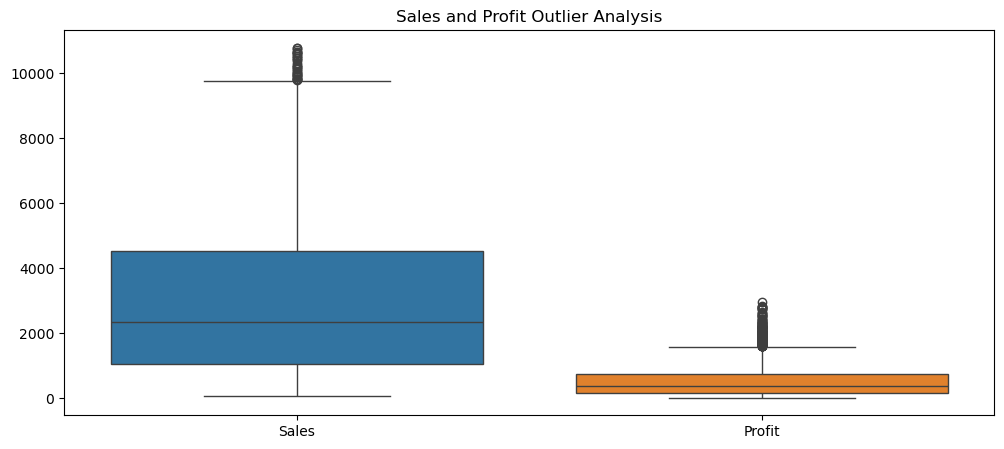

In [ ]:
# Visualize Outliers
plt.figure(figsize=(12, 5))

sns.boxplot(data=df[['Sales', 'Profit']])

plt.title("Sales and Profit Outlier Analysis")

plt.show()

In [ ]:
# Investigate Sales Outliers by Product
sales_outlier_products = (
    sales_outliers
    .groupby('Product Name')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Transaction_Count=('Sales', 'count')
    )
    .sort_values('Total_Sales', ascending=False)
)

sales_outlier_products

,Total_Sales,Total_Profit,Transaction_Count
Product Name,,,
Camera,60066,11597.98,6
Keyboard,51156,8186.24,5
Monitor,42066,8520.82,4
Laptop,41904,9169.62,4
Smartphone,41067,8367.05,4
Smartwatch,30987,3107.54,3
Headphones,30024,4137.70,3
Tablet,29988,5335.10,3
Mouse,20511,4444.86,2


In [ ]:
# Investigate Profit Outliers by Product
profit_outlier_products = (
    profit_outliers
    .groupby('Product Name')
    .agg(
        Total_Profit=('Profit', 'sum'),
        Total_Sales=('Sales', 'sum'),
        Transaction_Count=('Profit', 'count')
    )
    .sort_values('Total_Profit', ascending=False)
)

profit_outlier_products

,Total_Profit,Total_Sales,Transaction_Count
Product Name,,,
Laptop,51404.92,207699,25
Monitor,47181.04,192923,24
Smartphone,45258.51,188616,23
Camera,38837.44,156709,19
Mouse,38392.06,154604,20
Printer,32960.16,134351,17
Smartwatch,31529.00,126948,17
Keyboard,28867.48,112208,14
Headphones,28429.54,121218,16


In [22]:
# Combine Sales and Profit outliers

outlier_records = df[
    (df['Sales'].isin(sales_outliers)) |
    (df['Profit'].isin(profit_outliers))
]

# Display important columns
outlier_records[
    ['Order Date', 'Product Name', 'Category',
     'Region', 'Quantity', 'Sales', 'Profit']
].sort_values(by='Profit', ascending=False).head()


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit


In [23]:
print("Sales Outliers:")
print("Type:", type(sales_outliers))
print("Shape:", sales_outliers.shape)
display(sales_outliers.head())

print("\nProfit Outliers:")
print("Type:", type(profit_outliers))
print("Shape:", profit_outliers.shape)
display(profit_outliers.head())

Sales Outliers:
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (35, 12)


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
32,2023-04-09,Laptop,Electronics,North,9,10773,1907.36,2023,4,April,2,2023-04
147,2022-10-23,Keyboard,Accessories,West,9,10035,1486.30,2022,10,October,4,2022-10
153,2024-08-08,Monitor,Accessories,North,9,10530,2387.63,2024,8,August,3,2024-08
267,2024-01-25,Tablet,Electronics,East,9,10188,2165.78,2024,1,January,1,2024-01
293,2023-08-08,Monitor,Accessories,North,9,10458,2799.48,2023,8,August,3,2023-08



Profit Outliers:
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (184, 12)


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Year_Month
12,2023-12-21,Tablet,Electronics,North,7,7462,2166.17,2023,12,December,4,2023-12
32,2023-04-09,Laptop,Electronics,North,9,10773,1907.36,2023,4,April,2,2023-04
55,2023-12-28,Headphones,Accessories,East,7,8155,1587.91,2023,12,December,4,2023-12
60,2022-09-26,Headphones,Accessories,South,7,6895,1596.35,2022,9,September,3,2022-09
92,2022-12-14,Camera,Electronics,South,7,7518,1655.91,2022,12,December,4,2022-12


In [24]:
# Combine Sales and Profit outlier records
outlier_records = pd.concat([
    sales_outliers,
    profit_outliers
])

# Remove duplicate transactions
outlier_records = outlier_records[
    ~outlier_records.index.duplicated()
]

# Display total unique outlier transactions
print("Total unique outlier transactions:", len(outlier_records))

# Display the top 20 transactions by Profit
display(
    outlier_records[
        ['Order Date', 'Product Name', 'Category',
         'Region', 'Quantity', 'Sales', 'Profit']
    ].sort_values(by='Profit', ascending=False).head(20)
)

Total unique outlier transactions: 195


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
2392,2023-02-02,Laptop,Electronics,South,9,10620,2946.93
2347,2022-11-16,Keyboard,Accessories,South,9,10629,2843.54
293,2023-08-08,Monitor,Accessories,North,9,10458,2799.48
2531,2023-12-08,Camera,Electronics,South,9,9936,2797.45
1774,2023-03-16,Tablet,Electronics,South,9,9423,2794.89
3490,2023-05-14,Laptop,Electronics,West,9,9702,2771.49
1879,2023-01-03,Camera,Electronics,North,9,9180,2752.84
1127,2023-09-29,Keyboard,Accessories,South,9,10782,2730.14
1126,2024-04-21,Smartphone,Electronics,South,9,10314,2729.60
1035,2023-01-12,Camera,Electronics,East,8,9392,2651.84


In [25]:
# Count outlier transactions for each product
product_outliers = (
    outlier_records
    .groupby('Product Name')
    .agg(
        Outlier_Transactions=('Product Name', 'count'),
        Avg_Quantity=('Quantity', 'mean'),
        Avg_Sales=('Sales', 'mean'),
        Avg_Profit=('Profit', 'mean'),
        Total_Outlier_Sales=('Sales', 'sum'),
        Total_Outlier_Profit=('Profit', 'sum')
    )
)

# Count total transactions for each product
product_total = (
    df.groupby('Product Name')
    .size()
    .rename('Total_Transactions')
)

# Combine both results
product_analysis = product_outliers.join(product_total)

# Calculate outlier percentage for each product
product_analysis['Outlier_Rate_%'] = (
    product_analysis['Outlier_Transactions'] /
    product_analysis['Total_Transactions'] * 100
)

# Sort by number of outlier transactions
product_analysis = product_analysis.sort_values(
    by='Outlier_Transactions',
    ascending=False
)

display(product_analysis.round(2))

,Outlier_Transactions,Avg_Quantity,Avg_Sales,Avg_Profit,Total_Outlier_Sales,Total_Outlier_Profit,Total_Transactions,Outlier_Rate_%
Product Name,,,,,,,,
Laptop,25,8.32,8307.96,2056.20,207699,51404.92,336,7.44
Monitor,24,8.17,8038.46,1965.88,192923,47181.04,364,6.59
Smartphone,23,8.13,8200.70,1967.76,188616,45258.51,330,6.97
Camera,21,8.19,8424.48,1986.40,176914,41714.34,363,5.79
Mouse,20,7.95,7730.20,1919.60,154604,38392.06,347,5.76
Smartwatch,19,7.74,7758.16,1729.43,147405,32859.22,363,5.23
Headphones,18,7.94,7842.33,1709.58,141162,30772.51,339,5.31
Printer,18,7.89,8055.94,1884.53,145007,33921.46,357,5.04
Keyboard,17,8.29,8350.18,1851.77,141953,31480.04,351,4.84


In [26]:
# Identify outlier transactions using their original indexes

df['Transaction_Type'] = 'Normal'

df.loc[
    df.index.isin(outlier_records.index),
    'Transaction_Type'
] = 'Outlier'


# Compare normal and outlier transactions product-wise

comparison = (
    df.groupby(['Product Name', 'Transaction_Type'])
    .agg(
        Transactions=('Product Name', 'count'),
        Avg_Quantity=('Quantity', 'mean'),
        Avg_Sales=('Sales', 'mean'),
        Avg_Profit=('Profit', 'mean')
    )
    .round(2)
)

display(comparison)

Transactions  Avg_Quantity  Avg_Sales  \
Product Name Transaction_Type                                          
Camera       Normal                     342          4.75    2925.34   
             Outlier                     21          8.19    8424.48   
Headphones   Normal                     321          4.55    2640.11   
             Outlier                     18          7.94    7842.33   
Keyboard     Normal                     334          4.62    2642.38   
             Outlier                     17          8.29    8350.18   
Laptop       Normal                     311          4.66    2566.48   
             Outlier                     25          8.32    8307.96   
Monitor      Normal                     340          4.94    2844.49   
             Outlier                     24          8.17    8038.46   
Mouse        Normal                     327          4.87    2812.83   
             Outlier                     20          7.95    7730.20   
Printer      Normal                     339          4.70    2800.03   
             Outlier                     18          7.89    8055.94   
Smartphone   Normal                     307          4.66    2869.92   
             Outlier                     23          8.13    8200.70   
Smartwatch   Normal                     344          4.83    2621.53   
             Outlier                     19          7.74    7758.16   
Tablet       Normal                     340          4.85    2757.13   
             Outlier                     10          8.40    8650.30   

                               Avg_Profit  
Product Name Transaction_Type              
Camera       Normal                485.14  
             Outlier              1986.40  
Headphones   Normal                441.45  
             Outlier              1709.58  
Keyboard     Normal                432.14  
             Outlier              1851.77  
Laptop       Normal                432.00  
             Outlier              2056.20  
Monitor      Normal                455.43  
             Outlier              1965.88  
Mouse        Normal                450.68  
             Outlier              1919.60  
Printer      Normal                446.82  
             Outlier              1884.53  
Smartphone   Normal                449.64  
             Outlier              1967.76  
Smartwatch   Normal                424.82  
             Outlier              1729.43  
Tablet       Normal                431.39  
             Outlier              2083.38

In [27]:
# Calculate additional business metrics

df['Sales_Per_Unit'] = df['Sales'] / df['Quantity']

df['Profit_Per_Unit'] = df['Profit'] / df['Quantity']

df['Profit_Margin_%'] = (
    df['Profit'] / df['Sales']
) * 100


# Compare normal and outlier transactions

unit_analysis = (
    df.groupby('Transaction_Type')
    .agg(
        Total_Transactions=('Quantity', 'count'),
        Avg_Quantity=('Quantity', 'mean'),
        Avg_Sales=('Sales', 'mean'),
        Avg_Profit=('Profit', 'mean'),
        Avg_Sales_Per_Unit=('Sales_Per_Unit', 'mean'),
        Avg_Profit_Per_Unit=('Profit_Per_Unit', 'mean'),
        Avg_Profit_Margin=('Profit_Margin_%', 'mean')
    )
    .round(2)
)

display(unit_analysis)

,Total_Transactions,Avg_Quantity,Avg_Sales,Avg_Profit,Avg_Sales_Per_Unit,Avg_Profit_Per_Unit,Avg_Profit_Margin
Transaction_Type,,,,,,,
Normal,3305,4.74,2748.89,445.04,593.48,98.44,16.97
Outlier,195,8.10,8116.85,1917.02,1006.02,239.82,24.17


In [28]:
# Compare product performance between Normal and Outlier transactions

product_unit_comparison = (
    df.groupby(['Product Name', 'Transaction_Type'])
    .agg(
        Transactions=('Quantity', 'count'),
        Avg_Quantity=('Quantity', 'mean'),
        Avg_Sales_Per_Unit=('Sales_Per_Unit', 'mean'),
        Avg_Profit_Per_Unit=('Profit_Per_Unit', 'mean'),
        Avg_Profit_Margin=('Profit_Margin_%', 'mean')
    )
    .round(2)
)

display(product_unit_comparison)

Transactions  Avg_Quantity  Avg_Sales_Per_Unit  \
Product Name Transaction_Type                                                   
Camera       Normal                     342          4.75              625.06   
             Outlier                     21          8.19             1031.81   
Headphones   Normal                     321          4.55              599.99   
             Outlier                     18          7.94              991.39   
Keyboard     Normal                     334          4.62              583.51   
             Outlier                     17          8.29             1011.35   
Laptop       Normal                     311          4.66              569.74   
             Outlier                     25          8.32              999.56   
Monitor      Normal                     340          4.94              587.56   
             Outlier                     24          8.17              992.71   
Mouse        Normal                     327          4.87              595.23   
             Outlier                     20          7.95              983.10   
Printer      Normal                     339          4.70              614.68   
             Outlier                     18          7.89             1028.72   
Smartphone   Normal                     307          4.66              607.59   
             Outlier                     23          8.13             1009.26   
Smartwatch   Normal                     344          4.83              561.21   
             Outlier                     19          7.74              998.42   
Tablet       Normal                     340          4.85              590.13   
             Outlier                     10          8.40             1029.10   

                               Avg_Profit_Per_Unit  Avg_Profit_Margin  
Product Name Transaction_Type                                          
Camera       Normal                         106.51              17.44  
             Outlier                        245.46              23.97  
Headphones   Normal                         100.08              17.18  
             Outlier                        219.68              22.53  
Keyboard     Normal                          94.93              16.92  
             Outlier                        227.14              22.86  
Laptop       Normal                          96.16              17.14  
             Outlier                        248.65              25.05  
Monitor      Normal                          97.01              16.79  
             Outlier                        243.10              24.89  
Mouse        Normal                          98.68              16.85  
             Outlier                        245.22              25.17  
Printer      Normal                         101.44              16.92  
             Outlier                        242.31              24.09  
Smartphone   Normal                          98.87              16.65  
             Outlier                        244.85              24.44  
Smartwatch   Normal                          94.32              17.01  
             Outlier                        228.36              23.56  
Tablet       Normal                          96.31              16.76  
             Outlier                        250.78              24.59

In [29]:
# Category-wise comparison of Normal and Outlier transactions

category_analysis = (
    df.groupby(['Category', 'Transaction_Type'])
    .agg(
        Transactions=('Category', 'count'),
        Avg_Quantity=('Quantity', 'mean'),
        Avg_Sales=('Sales', 'mean'),
        Avg_Profit=('Profit', 'mean'),
        Avg_Sales_Per_Unit=('Sales_Per_Unit', 'mean'),
        Avg_Profit_Per_Unit=('Profit_Per_Unit', 'mean'),
        Avg_Profit_Margin=('Profit_Margin_%', 'mean')
    )
    .round(2)
)

display(category_analysis)

Transactions  Avg_Quantity  Avg_Sales  \
Category    Transaction_Type                                          
Accessories Normal                    1322          4.75    2735.97   
            Outlier                     79          8.09    7982.81   
Electronics Normal                    1644          4.75    2748.75   
            Outlier                     98          8.14    8236.09   
Office      Normal                     339          4.70    2800.03   
            Outlier                     18          7.89    8055.94   

                              Avg_Profit  Avg_Sales_Per_Unit  \
Category    Transaction_Type                                   
Accessories Normal                444.98              591.45   
            Outlier              1871.21              993.99   
Electronics Normal                444.72              590.75   
            Outlier              1959.91             1011.54   
Office      Normal                446.82              614.68   
            Outlier              1884.53             1028.72   

                              Avg_Profit_Per_Unit  Avg_Profit_Margin  
Category    Transaction_Type                                          
Accessories Normal                          97.64              16.94  
            Outlier                        234.86              23.99  
Electronics Normal                          98.46              17.00  
            Outlier                        243.36              24.34  
Office      Normal                         101.44              16.92  
            Outlier                        242.31              24.09

In [30]:
# Region-wise comparison of Normal and Outlier transactions

region_analysis = (
    df.groupby(['Region', 'Transaction_Type'])
    .agg(
        Transactions=('Region', 'count'),
        Avg_Quantity=('Quantity', 'mean'),
        Avg_Sales=('Sales', 'mean'),
        Avg_Profit=('Profit', 'mean'),
        Avg_Sales_Per_Unit=('Sales_Per_Unit', 'mean'),
        Avg_Profit_Per_Unit=('Profit_Per_Unit', 'mean'),
        Avg_Profit_Margin=('Profit_Margin_%', 'mean')
    )
    .round(2)
)

display(region_analysis)

Transactions  Avg_Quantity  Avg_Sales  Avg_Profit  \
Region Transaction_Type                                                      
East   Normal                     810          4.81    2802.45      454.36   
       Outlier                     51          8.06    7943.69     1899.11   
North  Normal                     818          4.62    2649.38      427.40   
       Outlier                     40          8.12    8039.50     1917.59   
South  Normal                     842          4.78    2759.28      447.45   
       Outlier                     41          8.15    8200.85     1984.14   
West   Normal                     835          4.77    2783.96      450.84   
       Outlier                     63          8.08    8251.48     1887.46   

                         Avg_Sales_Per_Unit  Avg_Profit_Per_Unit  \
Region Transaction_Type                                            
East   Normal                        600.43                99.81   
       Outlier                       993.37               239.54   
North  Normal                        583.19                96.61   
       Outlier                       989.80               237.67   
South  Normal                        591.14                98.17   
       Outlier                      1008.63               245.42   
West   Normal                        599.19                99.18   
       Outlier                      1024.84               237.77   

                         Avg_Profit_Margin  
Region Transaction_Type                     
East   Normal                        17.07  
       Outlier                       24.46  
North  Normal                        16.91  
       Outlier                       24.46  
South  Normal                        16.87  
       Outlier                       24.50  
West   Normal                        17.03  
       Outlier                       23.55

In [31]:
# Correlation between Quantity, Sales and Profit

print("Correlation across all transactions:")
display(
    df[['Quantity', 'Sales', 'Profit']].corr().round(3)
)

print("\nCorrelation in Normal transactions:")
display(
    df[df['Transaction_Type'] == 'Normal']
    [['Quantity', 'Sales', 'Profit']]
    .corr()
    .round(3)
)

print("\nCorrelation in Outlier transactions:")
display(
    df[df['Transaction_Type'] == 'Outlier']
    [['Quantity', 'Sales', 'Profit']]
    .corr()
    .round(3)
)

Correlation across all transactions:


,Quantity,Sales,Profit
Quantity,1.000,0.662,0.561
Sales,0.662,1.000,0.833
Profit,0.561,0.833,1.000



Correlation in Normal transactions:


,Quantity,Sales,Profit
Quantity,1.000,0.623,0.523
Sales,0.623,1.000,0.797
Profit,0.523,0.797,1.000



Correlation in Outlier transactions:


,Quantity,Sales,Profit
Quantity,1.000,0.572,0.172
Sales,0.572,1.000,0.216
Profit,0.172,0.216,1.000


During the Data Quality Assessment, I identified 35 Sales outlier records and 184 Profit outlier records. After combining both groups and removing 24 overlapping records, I found 195 unique transactions out of 3,500 transactions.

Instead of removing these records, I investigated them to understand why their Sales and Profit values were unusually high.

First, I compared normal transactions with outlier transactions. I found that outlier transactions had a higher average quantity of 8.10 units, compared with 4.74 units in normal transactions. Their average Sales and Profit were also significantly higher.

Next, I calculated Sales per Unit, Profit per Unit and Profit Margin. The results showed that outlier transactions also had higher per-unit values and a higher average Profit Margin of 24.17%, compared with 16.97% for normal transactions.

I then performed product-wise, category-wise and regional analysis. The same general pattern appeared across all products, categories and regions. Therefore, the outliers were not limited to one particular product or location.

Finally, I performed correlation analysis to understand the relationships between Quantity, Sales and Profit.

Based on the complete investigation, I found that unusually high Sales and Profit values were associated with higher transaction quantities and higher per-unit Sales and Profit.

However, the dataset does not contain detailed selling prices, purchase costs, discounts or promotional information. Therefore, I cannot confirm the exact business reason behind these values.

I did not remove these records because I found no evidence that they were incorrect. I retained them for further analysis.

### Overall Statistical Observations
What does the overall dataset tell us about transaction quantity, Sales and Profit?

In [32]:
# Calculate overall statistics
overall_stats = df[['Quantity', 'Sales', 'Profit']].agg([
    'count',
    'sum',
    'mean',
    'median',
    'std',
    'min',
    'max'
]).T

overall_stats = overall_stats.round(2)

display(overall_stats)

,count,sum,mean,median,std,min,max
Quantity,3500.0,17261.00,4.93,5.00,2.58,1.00,9.00
Sales,3500.0,10667881.00,3047.97,2350.50,2440.21,51.00,10782.00
Profit,3500.0,1844665.21,527.05,361.07,504.14,6.97,2946.93


In [33]:
# Calculate overall profit margin
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()

overall_profit_margin = (total_profit / total_sales) * 100

print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")

Total Sales: ₹10,667,881.00
Total Profit: ₹1,844,665.21
Overall Profit Margin: 17.29%


In [34]:
eda_summary = [
    "The dataset contains 3,500 transactions.",
    "Total Sales are ₹10,667,881.00.",
    "Total Profit is ₹1,844,665.21.",
    "Total Quantity sold is 17,261 units.",
    "The overall Profit Margin is 17.29%.",
    "Average Sales per transaction are ₹3,047.97.",
    "Average Profit per transaction is ₹527.05.",
    "Median Sales are lower than average Sales.",
    "Median Profit is lower than average Profit.",
    "195 transactions were identified as outliers.",
    "Outlier transactions represent approximately 5.57% of the dataset."
]

for i, observation in enumerate(eda_summary, start=1):
    print(f"{i}. {observation}")

1. The dataset contains 3,500 transactions.
2. Total Sales are ₹10,667,881.00.
3. Total Profit is ₹1,844,665.21.
4. Total Quantity sold is 17,261 units.
5. The overall Profit Margin is 17.29%.
6. Average Sales per transaction are ₹3,047.97.
7. Average Profit per transaction is ₹527.05.
8. Median Sales are lower than average Sales.
9. Median Profit is lower than average Profit.
10. 195 transactions were identified as outliers.
11. Outlier transactions represent approximately 5.57% of the dataset.
